In [4]:
import torch
import yaml

# Definiamo i percorsi basandoci su quello che hai trovato
checkpoint_path = "./logging/checkpoints/model_best.pth"
config_path = "./logging/config_0.yaml"
output_path = "./logging/checkpoints/modeldef_19_7_new.pth"

print(f"Caricamento checkpoint: {checkpoint_path}")
checkpoint = torch.load(checkpoint_path, map_location='cpu')

print(f"Caricamento configurazione: {config_path}")
with open(config_path, 'r') as f:
    config_data = yaml.safe_load(f)

# Inseriamo i dati mancanti
checkpoint['config'] = config_data

# Salviamo il nuovo file "riparato"
torch.save(checkpoint, output_path)
print(f"Successo! Nuovo checkpoint salvato in: {output_path}")

Caricamento checkpoint: ./logging/checkpoints/model_best.pth
Caricamento configurazione: ./logging/config_0.yaml
Successo! Nuovo checkpoint salvato in: ./logging/checkpoints/modeldef_19_7_new.pth


In [22]:
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import openslide
from pprint import pprint

slide = openslide.OpenSlide("/home/jovyan/path-vol/data/PDL1_WSI/20-5312 PDL-1 22C3 Ab.svs")
with open("/home/jovyan/path-vol/Flusso1/NuLite/Prova_png_HEM_rgb/cell_detection/cell_detection.geojson", "r") as f:
    cells = json.load(f)

#print(slide.dimensions)
#print(slide.level_downsamples)
#pprint(dict(slide.properties))

#LEVEL = slide.level_count - 1
LEVEL = 2
ds    = slide.level_downsamples[LEVEL]
w, h  = slide.level_dimensions[LEVEL]
print(f"Livello {LEVEL}: {w}x{h} px  (downsample {ds:.1f}x)")
print(f"Totale feature nel GeoJSON: {len(cells)}")

region     = slide.read_region((0, 0), LEVEL, (w, h))
region_rgb = np.array(region.convert("RGB"))

class_data = defaultdict(lambda: {"xs": [], "ys": [], "color": None})

for cell in cells:
    coords = np.array(cell["geometry"]["coordinates"])
    color  = [c / 255 for c in cell["properties"]["classification"]["color"]]
    name   = cell["properties"]["classification"]["name"]

    if coords.ndim == 1:
        coords = coords[np.newaxis, :]

    px = coords[:, 0] / ds
    py = coords[:, 1] / ds

    class_data[name]["xs"].extend(px.tolist())
    class_data[name]["ys"].extend(py.tolist())
    class_data[name]["color"] = color

for name, d in class_data.items():
    print(f"  {name}: {len(d['xs'])} nuclei")

fig, ax = plt.subplots(figsize=(14, 14))
ax.imshow(region_rgb)

for name, d in class_data.items():
    ax.scatter(d["xs"], d["ys"],
               c=[d["color"]], s=1,
               zorder=5, alpha=0.7,
               label=name)

ax.set_xlim(0, w)
ax.set_ylim(h, 0)
ax.legend(loc="upper right", markerscale=5)
ax.axis("off")
plt.tight_layout()
plt.savefig("/home/jovyan/path-vol/NuLite/20-5312 PDL-1 22C3 Ab.png", dpi=150, bbox_inches="tight")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/home/jovyan/path-vol/Flusso1/NuLite/Prova_png_HEM_rgb/cell_detection/cell_detection.geojson'

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



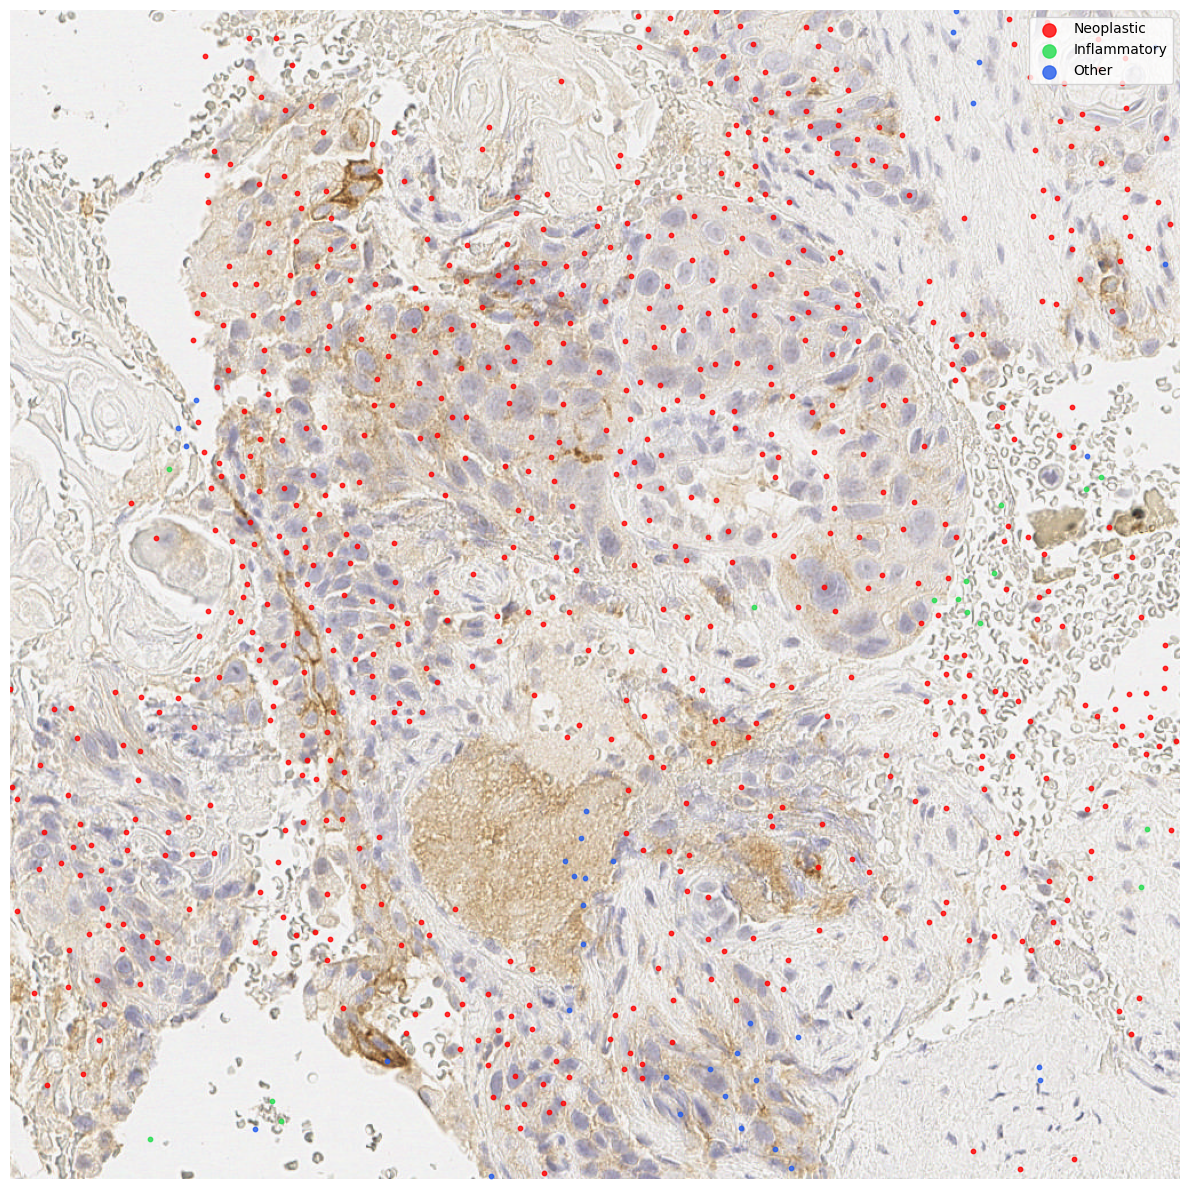

In [68]:
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import openslide

slide = openslide.OpenSlide("/home/jovyan/path-vol/NuLite/Prova/20-5312 PDL-1 22C3 Ab.svs")
with open("/home/jovyan/path-vol/Flusso1/NuLite/Prova_png_HEM_rgb/cell_detection/cell_detection.geojson", "r") as f:
    cells = json.load(f)
print(cells[0])
# ── CONFIG ──
LEVEL    = 0
REGION_X = 30000
REGION_Y = 15000
REGION_W = 1024
REGION_H = 1024

# ── Leggi regione ──
ds   = slide.level_downsamples[LEVEL]
w_lv = int(REGION_W / ds)
h_lv = int(REGION_H / ds)

region     = slide.read_region((REGION_X, REGION_Y), LEVEL, (w_lv, h_lv))
region_rgb = np.array(region.convert("RGB"))

# ── Raggruppa per classe ──
class_data = defaultdict(lambda: {"xs": [], "ys": [], "color": None})

for cell in cells:
    coords = np.array(cell["geometry"]["coordinates"])
    color  = [c / 255 for c in cell["properties"]["classification"]["color"]]
    name   = cell["properties"]["classification"]["name"]

    # se è un singolo punto [x, y] lo rendiamo (1, 2)
    if coords.ndim == 1:
        coords = coords[np.newaxis, :]

    mask = (
        (coords[:, 0] >= REGION_X) & (coords[:, 0] <= REGION_X + REGION_W) &
        (coords[:, 1] >= REGION_Y) & (coords[:, 1] <= REGION_Y + REGION_H)
    )
    pts = coords[mask]
    print(pts)
    if len(pts) == 0:
        continue

    px = (pts[:, 0] - REGION_X) / ds
    py = (pts[:, 1] - REGION_Y) / ds

    class_data[name]["xs"].extend(px.tolist())
    class_data[name]["ys"].extend(py.tolist())
    class_data[name]["color"] = color
    

# ── Plot ──
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(region_rgb)

for name, d in class_data.items():
    ax.scatter(d["xs"], d["ys"],
               c=[d["color"]], s=10,
               zorder=5, alpha=0.8,
               label=name)

ax.set_xlim(0, w_lv)
ax.set_ylim(h_lv, 0)
ax.legend(loc="upper right", markerscale=3)
ax.axis("off")
plt.tight_layout()
plt.savefig("/home/jovyan/path-vol/NuLite/20-5312 PDL-1 22C3 Ab_patch.png", dpi=150, bbox_inches="tight")
plt.show()

In [142]:
# INFERENZA SU UN'UNICA PATCH PNG

from PIL import Image, ImageFile
import numpy as np
import json
import matplotlib.pyplot as plt
from collections import defaultdict

ImageFile.LOAD_TRUNCATED_IMAGES = True

region_rgb = np.array(Image.open("./Prova_png/patches/20-5312 PDL-1 22C3 Ab_12_29.png"))

with open("./Prova_png_HEM_rgb/patches/cell_detection/cell_detection.geojson", "r") as f:
    geojson = json.load(f)

h, w = region_rgb.shape[:2]

class_data = defaultdict(lambda: {"xs": [], "ys": [], "color": None})

total = 0
for feature in geojson:  
    coords = feature["geometry"]["coordinates"]  
    color = [c / 255 for c in feature["properties"]["classification"]["color"]]
    name = feature["properties"]["classification"]["name"]

    coords = np.array(coords)  # shape: (N, 2)
    if coords.ndim == 1:
        coords = coords[np.newaxis, :]  # caso singolo punto

    class_data[name]["xs"].extend(coords[:, 0].tolist())
    class_data[name]["ys"].extend(coords[:, 1].tolist())
    class_data[name]["color"] = color
    total += len(coords)

print(f"Totale nuclei: {total}")
for name, d in class_data.items():
    print(f"  {name}: {len(d['xs'])} nuclei")

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(region_rgb)
for name, d in class_data.items():
    ax.scatter(d["xs"], d["ys"], c=[d["color"]], s=10, alpha=0.7, label=name)
ax.set_xlim(0, w)
ax.set_ylim(h, 0)
ax.legend()
ax.axis("off")
plt.tight_layout()
plt.savefig("patch_inference_result.png", dpi=150)
plt.show()    

FileNotFoundError: [Errno 2] No such file or directory: './Prova_png_HEM_rgb/patches/cell_detection/cell_detection.geojson'

Totale nuclei: 620
  Neoplastic: 259 nuclei
  Inflammatory: 177 nuclei
  Connective: 184 nuclei


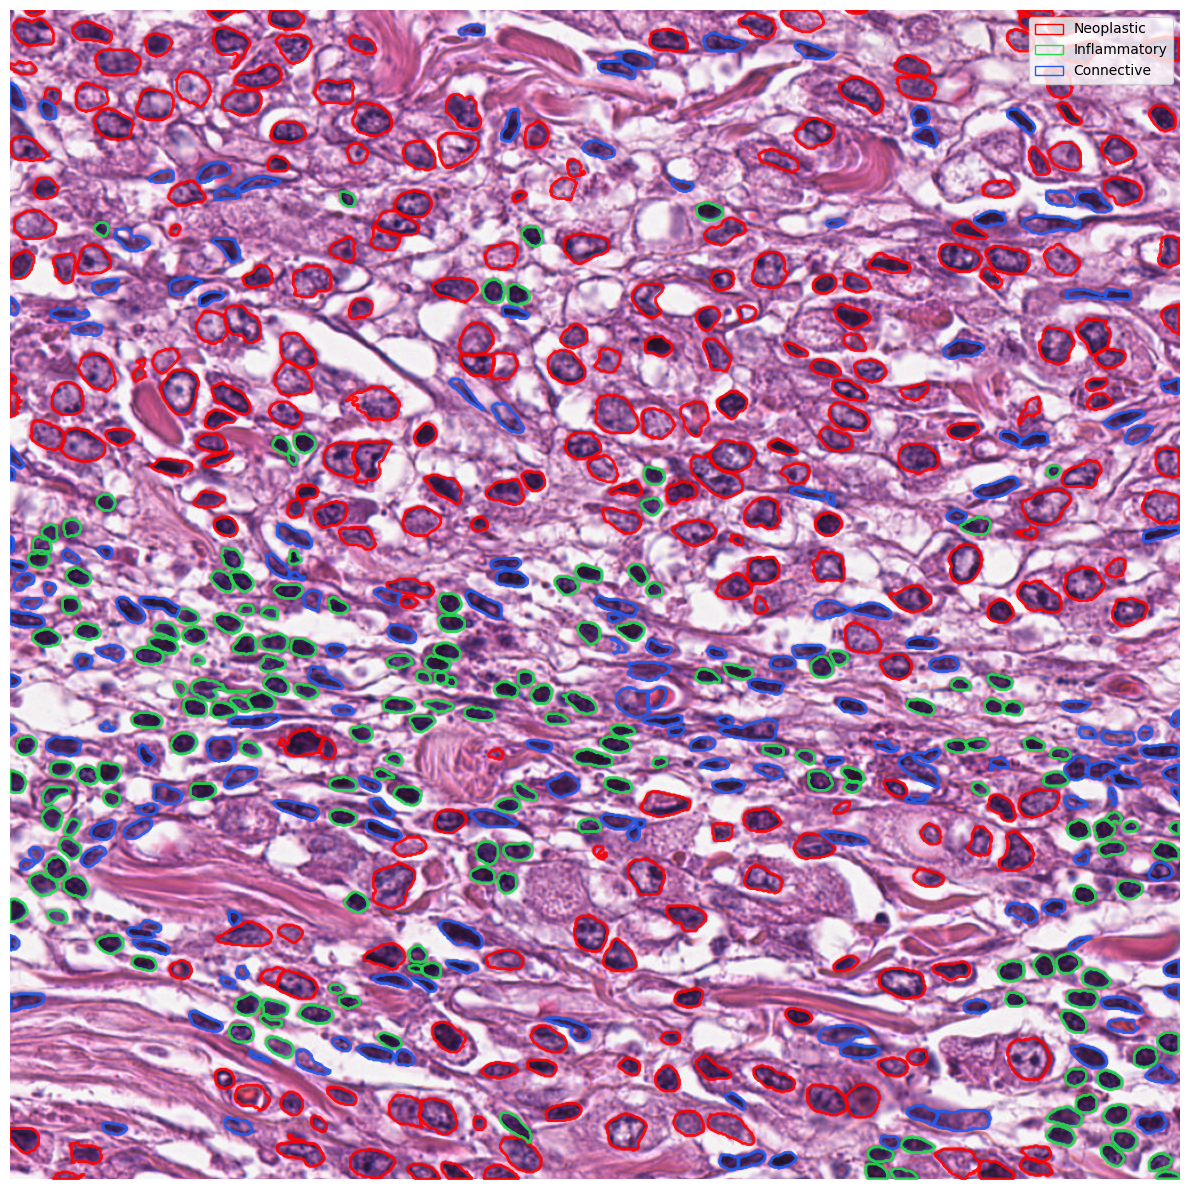

In [19]:
from PIL import Image, ImageFile
import numpy as np
import json
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from collections import defaultdict

ImageFile.LOAD_TRUNCATED_IMAGES = True

region_rgb = np.array(Image.open("/home/jovyan/path-vol/Flusso1/Decolorazione/Glysac/Test/images_rgb/AGC1_tumor_11.png"))

with open("/home/jovyan/path-vol/NuLite/glysac_inference_out/geojsons/AGC1_tumor_11.geojson", "r") as f:
    geojson = json.load(f)

h, w = region_rgb.shape[:2]

# Raggruppa poligoni per classe
class_data = defaultdict(lambda: {"polygons": [], "color": None})

total = 0
for feature in geojson:
    name = feature["properties"]["classification"]["name"]
    color = [c / 255 for c in feature["properties"]["classification"]["color"]]
    multipolygon = feature["geometry"]["coordinates"]  # lista di poligoni

    for polygon_group in multipolygon:
        for ring in polygon_group:
            exterior_ring = polygon_group[0]  # Precedentemente stavo contando i pixel delle boundaries, non 
                                                # le cellule, per risolvere considero solo il primo elemento
            coords = np.array(exterior_ring)
            # coords = np.array(ring)  # shape: (N, 2) -> [x, y]
            if coords.ndim == 2 and len(coords) >= 3:
                class_data[name]["polygons"].append(coords)
                class_data[name]["color"] = color
                total += 1

print(f"Totale nuclei: {total}")
for name, d in class_data.items():
    print(f"  {name}: {len(d['polygons'])} nuclei")

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(region_rgb)

legend_handles = []
for name, d in class_data.items():
    color = d["color"]
    patches = []
    for coords in d["polygons"]:
        poly = Polygon(coords, closed=True)
        patches.append(poly)
    
    pc = PatchCollection(
        patches,
        facecolor="none",
        edgecolor=[color],
        linewidth=2.0,
        alpha=0.9
    )
    ax.add_collection(pc)
    legend_handles.append(mpatches.Patch(edgecolor=color, facecolor="none", label=name))

ax.set_xlim(0, w)
ax.set_ylim(h, 0)
ax.legend(handles=legend_handles, loc="upper right", fontsize=10)
ax.axis("off")
plt.tight_layout()
plt.savefig("/home/jovyan/path-vol/Flusso1/NuLite/patch_inference_result_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
import numpy as np

arr = np.load("/home/jovyan/path-vol/Flusso1/Decolorazione/Consep/fold1/labels/test_1.npy", allow_pickle=True)
print(arr)

{'inst_map': array([[  0,   0,   0, ..., 260, 260, 260],
       [  0,   0,   0, ..., 260, 260, 260],
       [  0,   0,   0, ..., 260, 260, 260],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=int32), 'type_map': array([[0, 0, 0, ..., 3, 3, 3],
       [0, 0, 0, ..., 3, 3, 3],
       [0, 0, 0, ..., 3, 3, 3],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=int32)}
